In [169]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

In [170]:
def read_original_data():
    return pd.read_csv("data/exam_score_data_na.csv", sep=";")

In [171]:
data = read_original_data()

In [172]:
data.info()
print("---")
print(data.isnull().sum())
print("---")
print(data.shape)

<class 'pandas.DataFrame'>
RangeIndex: 6998 entries, 0 to 6997
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         6998 non-null   int64  
 1   assignment_completion_rate  6998 non-null   float64
 2   study_hours_per_day         6998 non-null   float64
 3   self_study_hours            6998 non-null   float64
 4   online_learning_hours       6998 non-null   float64
 5   sleep_hours                 6998 non-null   float64
 6   daily_screen_time           6998 non-null   float64
 7   stress_level                6998 non-null   int64  
 8   online_course_hours         6998 non-null   float64
 9   exam_preparation_days       6998 non-null   int64  
 10  exam_anxiety_level          6998 non-null   float64
 11  exam_score                  6925 non-null   float64
dtypes: float64(9), int64(3)
memory usage: 656.2 KB
---
age                            0
assignment_comple

# ORTALAMA (MEAN) ile eksik veri doldurma

In [173]:
meanData = read_original_data()
print(meanData["exam_score"][:30])
fea_transformer = SimpleImputer(strategy="mean")
mean_values = fea_transformer.fit_transform(meanData[["exam_score"]])
meanData["exam_score"] = pd.DataFrame(mean_values)
print(meanData["exam_score"][:30])

0     90.40
1     86.21
2     76.11
3     79.74
4     50.66
5     67.90
6     53.86
7       NaN
8       NaN
9       NaN
10      NaN
11      NaN
12      NaN
13      NaN
14      NaN
15      NaN
16      NaN
17      NaN
18      NaN
19      NaN
20      NaN
21    59.96
22      NaN
23    72.44
24    72.34
25      NaN
26      NaN
27    47.83
28    73.88
29    58.27
Name: exam_score, dtype: float64
0     90.400000
1     86.210000
2     76.110000
3     79.740000
4     50.660000
5     67.900000
6     53.860000
7     61.619801
8     61.619801
9     61.619801
10    61.619801
11    61.619801
12    61.619801
13    61.619801
14    61.619801
15    61.619801
16    61.619801
17    61.619801
18    61.619801
19    61.619801
20    61.619801
21    59.960000
22    61.619801
23    72.440000
24    72.340000
25    61.619801
26    61.619801
27    47.830000
28    73.880000
29    58.270000
Name: exam_score, dtype: float64


# ORTANCA (MEDIAN) ile eksik veri doldurma

In [174]:
medianData = read_original_data()
print(medianData["exam_score"][:30])
fea_transformer = SimpleImputer(strategy="median")
median_values = fea_transformer.fit_transform(medianData[["exam_score"]])
medianData["exam_score"] = pd.DataFrame(median_values)
print(medianData["exam_score"][:30])

0     90.40
1     86.21
2     76.11
3     79.74
4     50.66
5     67.90
6     53.86
7       NaN
8       NaN
9       NaN
10      NaN
11      NaN
12      NaN
13      NaN
14      NaN
15      NaN
16      NaN
17      NaN
18      NaN
19      NaN
20      NaN
21    59.96
22      NaN
23    72.44
24    72.34
25      NaN
26      NaN
27    47.83
28    73.88
29    58.27
Name: exam_score, dtype: float64
0     90.40
1     86.21
2     76.11
3     79.74
4     50.66
5     67.90
6     53.86
7     61.69
8     61.69
9     61.69
10    61.69
11    61.69
12    61.69
13    61.69
14    61.69
15    61.69
16    61.69
17    61.69
18    61.69
19    61.69
20    61.69
21    59.96
22    61.69
23    72.44
24    72.34
25    61.69
26    61.69
27    47.83
28    73.88
29    58.27
Name: exam_score, dtype: float64


# EN YAKIN KOMŞULAR (KNN) ile eksik veri doldurma

In [175]:
from sklearn.impute import KNNImputer

features = [
    "age",
    "assignment_completion_rate",
    "study_hours_per_day",
    "self_study_hours",
    "online_learning_hours",
    "sleep_hours",
    "daily_screen_time",
    "stress_level",
    "online_course_hours",
    "exam_preparation_days",
    "exam_anxiety_level",
    "exam_score",
]

knnData = read_original_data()
print(knnData["exam_score"][:20])
fea_transformer = KNNImputer(n_neighbors=3)
knn_values = fea_transformer.fit_transform(knnData[features])
knnData["exam_score"] = pd.DataFrame(knn_values)[features.index("exam_score")]
print(knnData["exam_score"][:20])

0     90.40
1     86.21
2     76.11
3     79.74
4     50.66
5     67.90
6     53.86
7       NaN
8       NaN
9       NaN
10      NaN
11      NaN
12      NaN
13      NaN
14      NaN
15      NaN
16      NaN
17      NaN
18      NaN
19      NaN
Name: exam_score, dtype: float64
0     90.400000
1     86.210000
2     76.110000
3     79.740000
4     50.660000
5     67.900000
6     53.860000
7     75.183333
8     55.243333
9     49.523333
10    50.430000
11    45.440000
12    62.790000
13    82.953333
14    60.523333
15    72.973333
16    69.550000
17    54.593333
18    58.840000
19    58.603333
Name: exam_score, dtype: float64


# knn ölçeklendirilmiş ile doldurma

In [176]:
from sklearn.preprocessing import StandardScaler

scaledKNNData = read_original_data()
scaler = StandardScaler()
scaled_data = scaler.fit_transform(scaledKNNData[features])
scaled_df = pd.DataFrame(scaled_data, columns=features)
fea_transformer = KNNImputer(n_neighbors=3)
knn_imputed_scaled = fea_transformer.fit_transform(scaled_df)
knn_imputed_original_scale = scaler.inverse_transform(knn_imputed_scaled)
scaledKNNData["exam_score"] = pd.DataFrame(knn_imputed_original_scale)[
    features.index("exam_score")
]

# Yineleyici (MICE) ile eksik veri doldurma

In [177]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

imp_data = read_original_data()
print(imp_data["exam_score"][:20])
imp_mean = IterativeImputer(random_state=0)
imp = imp_mean.fit_transform(imp_data[features])
imp_data["exam_score"] = pd.DataFrame(imp)[features.index("exam_score")]
print(imp_data["exam_score"][:20])

0     90.40
1     86.21
2     76.11
3     79.74
4     50.66
5     67.90
6     53.86
7       NaN
8       NaN
9       NaN
10      NaN
11      NaN
12      NaN
13      NaN
14      NaN
15      NaN
16      NaN
17      NaN
18      NaN
19      NaN
Name: exam_score, dtype: float64
0     90.400000
1     86.210000
2     76.110000
3     79.740000
4     50.660000
5     67.900000
6     53.860000
7     66.618900
8     58.086556
9     54.876617
10    63.598493
11    54.061455
12    60.411024
13    83.448693
14    64.547399
15    56.931386
16    64.557244
17    57.882605
18    46.351339
19    62.946024
Name: exam_score, dtype: float64


# Random Forest tabanlı eksik veri doldurma

In [178]:
from sklearn.ensemble import RandomForestRegressor

rf_data = read_original_data()

print(rf_data[:20])

train_data = rf_data[rf_data["exam_score"].notna()]
predict_data = rf_data[rf_data["exam_score"].isna()]

x_examScore = train_data[features]
y_examScore = train_data["exam_score"]

X_predict = predict_data[features]

rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=5, min_samples_leaf=4, random_state=42
)
rf_model.fit(x_examScore, y_examScore)

predicted_examScores = rf_model.predict(X_predict)
rf_data.loc[rf_data["exam_score"].isna(), "exam_score"] = predicted_examScores

print(rf_data[:20])

    age  assignment_completion_rate  study_hours_per_day  self_study_hours  \
0    20                       65.18                 4.94              2.63   
1    17                       76.53                 3.42              2.64   
2    18                       70.39                 1.06              0.83   
3    20                       75.06                 7.89              5.51   
4    16                       61.54                 2.63              2.29   
5    18                       65.46                 3.18              1.67   
6    18                       70.92                 3.35              2.11   
7    20                       72.83                 5.51              4.33   
8    15                       70.12                 2.42              1.65   
9    16                       61.53                 1.26              0.78   
10   20                       64.63                 1.47              1.04   
11   16                       65.89                 2.85        

# MAE, RMSE R2 metrikleri

In [179]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def calculate_imputation_metrics(y_true, y_pred, method_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"[{method_name}] MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

    return {"Metot": method_name, "MAE": mae, "RMSE": rmse, "R2": r2}


def evaluate_all_imputations(
    full_data, original_data, imputed_datasets, target_col="exam_score"
):
    missing_mask = original_data[target_col].isnull()

    y_true = full_data.loc[missing_mask, target_col]

    results = []
    for method_name, imputed_data in imputed_datasets.items():
        y_pred = imputed_data.loc[missing_mask, target_col]
        metrics = calculate_imputation_metrics(y_true, y_pred, method_name)
        results.append(metrics)

    return pd.DataFrame(results)


original_data = read_original_data()
fullData = pd.read_csv("data/exam_score_data.csv", sep=";")

imputed_datasets = {
    "Ortalama (Mean)": meanData,
    "Ortanca (Median)": medianData,
    "KNN": knnData,
    "KNN (Ölçeklendirilmiş)": scaledKNNData,
    "Yineleyici (MICE)": imp_data,
    "Random Forest": rf_data,
}

print("--- Eksik Veri Doldurma Performans Metrikleri ---")
sonuclar_df = evaluate_all_imputations(
    fullData, original_data, imputed_datasets, target_col="exam_score"
)

display(sonuclar_df)

--- Eksik Veri Doldurma Performans Metrikleri ---
[Ortalama (Mean)] MAE: 13.7202 | RMSE: 17.0269 | R2: -0.0000
[Ortanca (Median)] MAE: 13.7159 | RMSE: 17.0268 | R2: -0.0000
[KNN] MAE: 14.6084 | RMSE: 17.3113 | R2: -0.0337
[KNN (Ölçeklendirilmiş)] MAE: 13.7885 | RMSE: 16.7898 | R2: 0.0276
[Yineleyici (MICE)] MAE: 12.4595 | RMSE: 15.3352 | R2: 0.1888
[Random Forest] MAE: 13.7259 | RMSE: 17.0275 | R2: -0.0001


,Metot,MAE,RMSE,R2
0,Ortalama (Mean),13.720151,17.026943,-1.739843e-05
1,Ortanca (Median),13.715890,17.026795,-2.330188e-09
2,KNN,14.608356,17.311314,-3.369944e-02
3,KNN (Ölçeklendirilmiş),13.788539,16.789836,2.763996e-02
4,Yineleyici (MICE),12.459531,15.335242,1.888233e-01
5,Random Forest,13.725876,17.027497,-8.245160e-05


# performans kıyas grafiği

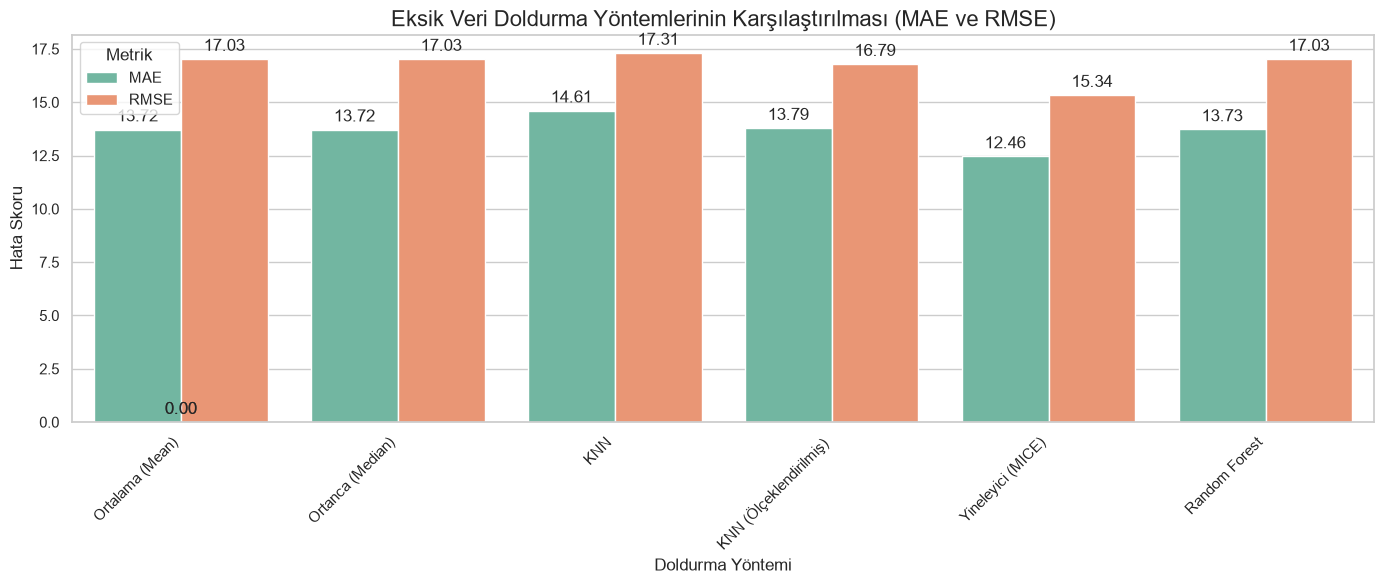

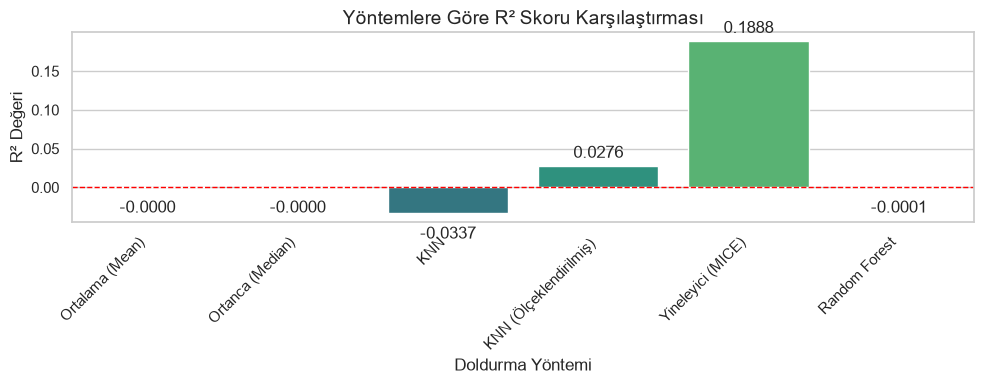

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

df_melted = sonuclar_df.melt(
    id_vars="Metot", value_vars=["MAE", "RMSE"], var_name="Metrik", value_name="Değer"
)

ax = sns.barplot(x="Metot", y="Değer", hue="Metrik", data=df_melted, palette="Set2")

plt.title(
    "Eksik Veri Doldurma Yöntemlerinin Karşılaştırılması (MAE ve RMSE)", fontsize=16
)
plt.xlabel("Doldurma Yöntemi", fontsize=12)
plt.ylabel("Hata Skoru", fontsize=12)
plt.xticks(rotation=45, ha="right") 
plt.legend(title="Metrik")

for p in ax.patches:
    ax.annotate(
        format(p.get_height(), ".2f"),
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 9),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

# R2 skoru için
plt.figure(figsize=(10, 4))
ax2 = sns.barplot(
    x="Metot", y="R2", data=sonuclar_df, hue="Metot", palette="viridis", legend=False
)
plt.title("Yöntemlere Göre R² Skoru Karşılaştırması", fontsize=14)
plt.xlabel("Doldurma Yöntemi", fontsize=12)
plt.ylabel("R² Değeri", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.axhline(0, color="red", linestyle="--", linewidth=1)

for p in ax2.patches:
    ax2.annotate(
        format(p.get_height(), ".4f"),
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 9 if p.get_height() >= 0 else -15),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()